# KAN-56 — EXP-16: Multi-Merchant Scalability & Generalization Validation
## for Explainable Slow-Moving Product Risk Detection in E-Commerce

**Phase**: Multi-Merchant Scalability, Cross-Category Generalization & Production Scale Validation
**Dependency**: EXP-15 (Production Hardening, Monitoring & MLOps Readiness)

**Core Paradigm**:
Validate whether the Explainable Slow-Moving Product Risk DSS can scale from the initial pilot cohort to a multi-merchant cohort across heterogeneous product categories and catalog scales while maintaining predictive accuracy, explainability, probabilistic calibration, and operational throughput.

**Research Questions**:
- **RQ1**: Does DSS maintain classification performance when evaluated on new out-of-distribution merchants?
- **RQ2**: Does the model generalize effectively across heterogeneous product categories?
- **RQ3**: Is probability calibration stable across diverse merchant distributions (ECE <= 0.02)?
- **RQ4**: Are SHAP top risk factors and Business Cause Tags consistent across domains?
- **RQ5**: Is the 4-Tier Decision Policy stable across merchants without priority inflation?
- **RQ6**: How does execution throughput (SKUs/sec) and API latency scale as catalog volume increases to 100,000+ SKUs?
- **RQ7**: What is the generalization gap (G_gap) between baseline research and out-of-distribution merchant cohorts?
- **RQ8**: Can the system process multiple concurrent merchant workloads without violating SLA targets?

In [1]:
import sys, os, json
import pandas as pd
from pathlib import Path
from IPython.display import display, Markdown, Image

PROJECT_ROOT = Path(os.getcwd()).parent if os.getcwd().endswith('notebooks') else Path(os.getcwd())
summary_json_path = PROJECT_ROOT / 'reports' / 'EXP-16_scalability' / 'generalization_summary.json'

if summary_json_path.exists():
    with open(summary_json_path, 'r', encoding='utf-8') as f:
        gen_summary = json.load(f)
else:
    sys.path.append(str(PROJECT_ROOT / 'scripts' / 'experiments'))
    from multi_merchant_scalability_validation import main as run_scale
    gen_summary = run_scale()

## 1. Multi-Merchant Cohort Demographics (N=10 Merchants, 8 Categories, 25,100 SKUs)

In [2]:
df_m = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-16_scalability' / 'merchant_generalization.csv')
display(df_m.style
    .set_caption('Multi-Merchant Evaluation Cohort Breakdown')
    .format({'high_risk_recall_pct': '{:.2f}%', 'precision_pct': '{:.2f}%', 'ece': '{:.4f}'})
)

df_cat = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-16_scalability' / 'category_generalization.csv')
display(df_cat.style.set_caption('Cross-Category Performance Breakdown (8 Product Categories)'))

,merchant_id,name,group,category,catalog_skus,high_risk_recall_pct,precision_pct,ece
0,M01,Fashion Hub,Group A,Fashion & Apparel,1200,98.10%,92.40%,0.0145
1,M02,Tech Gadgets,Group B,Electronics & Gadgets,2500,97.50%,91.80%,0.0162
2,M03,Glow Beauty,Group C,Cosmetics & Beauty,850,98.20%,93.10%,0.0138
3,M04,Daily FMCG,Group D,FMCG & Groceries,5000,97.40%,91.50%,0.0170
4,M05,Home Decor,Group E,Home & Living,1800,97.90%,92.20%,0.0150
5,M06,Sport Gear,Group F,Sports & Outdoors,950,98.00%,92.50%,0.0148
6,M07,Bling Accessories,Group G,Fashion Accessories,1500,97.70%,92.00%,0.0155
7,M08,Baby Care,Group H,Mom & Baby Care,1100,98.30%,93.40%,0.0132
8,M09,Office Depot,Group I,Office Supplies,2200,97.80%,92.30%,0.0152
9,M10,Mega Mart,Group J,Multi-Category Megastore,8000,97.60%,91.70%,0.0168


,category,merchants_count,total_skus,avg_high_risk_recall_pct,avg_precision_pct,avg_ece
0,Cosmetics & Beauty,1,850,98.200000,93.100000,0.013800
1,Electronics & Gadgets,1,2500,97.500000,91.800000,0.016200
2,FMCG & Groceries,1,5000,97.400000,91.500000,0.017000
3,Fashion & Apparel,1,1200,98.100000,92.400000,0.014500
4,Fashion Accessories,1,1500,97.700000,92.000000,0.015500
5,Home & Living,1,1800,97.900000,92.200000,0.015000
6,Mom & Baby Care,1,1100,98.300000,93.400000,0.013200
7,Multi-Category Megastore,1,8000,97.600000,91.700000,0.016800
8,Office Supplies,1,2200,97.800000,92.300000,0.015200
9,Sports & Outdoors,1,950,98.000000,92.500000,0.014800


## 2. Cross-Merchant Generalization & Generalization Gap (RQ1-RQ5, RQ7)

In [3]:
df_cross = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-16_scalability' / 'cross_merchant_performance.csv')
display(df_cross.style.set_caption('Cross-Merchant Generalization & Gap (G_gap <= 2.5%)'))

,eval_dimension,observed_metric,target_threshold,generalization_gap,status
0,High-Risk Recall (Critical/High),97.85%,>= 95.0%,0.58%,PASSED ✅
1,Overall Classification Precision,92.29%,>= 90.0%,0.30%,PASSED ✅
2,Macro F1-Score,94.99%,>= 92.0%,0.20%,PASSED ✅
3,Calibration ECE,0.0152,<= 0.0200,0.0012,PASSED ✅
4,Decision Policy Consistency,97.20%,>= 95.0%,0.00%,PASSED ✅
5,SHAP Evidence Direction Match,96.50%,>= 95.0%,0.00%,PASSED ✅


## 3. Scalability & Scale Stress Testing up to 100,000 SKUs (RQ6, RQ8)

In [4]:
df_scale = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-16_scalability' / 'scalability_benchmark.csv')
display(df_scale.style
    .set_caption('Workload Execution Throughput & Latency Benchmarks')
    .format({'throughput_skus_per_sec': '{:,.0f}', 'exec_time_sec': '{:.2f}s', 'max_cpu_pct': '{:.1f}%'})
)

df_fail = pd.read_csv(PROJECT_ROOT / 'reports' / 'EXP-16_scalability' / 'merchant_failure_analysis.csv')
display(df_fail.style.set_caption('Pipeline Failure & Stress Audit Log'))

,workload_level,sku_volume,exec_time_sec,throughput_skus_per_sec,avg_latency_ms,max_ram_mb,max_cpu_pct,success_rate_pct
0,Small (Baseline),1000,0.22s,"4,545",220,180,25.0%,100.000000
1,Medium (Production),10000,1.85s,"5,405",1850,350,45.0%,100.000000
2,Large (Scale Test),50000,8.40s,"5,952",8400,820,72.0%,100.000000
3,X-Large (Stress Test),100000,15.80s,"6,329",15800,1450,88.0%,100.000000


,failure_type,occurrences,resolution
0,Schema Violation,0,Validation Filter Blocked 0 Bad Rows
1,Memory Overflow,0,Chunked Batch Processing Preserved RAM <= 1.5GB


## 4. Multi-Merchant Scalability Visual Dashboard

### Multi-Merchant Scalability Dashboard

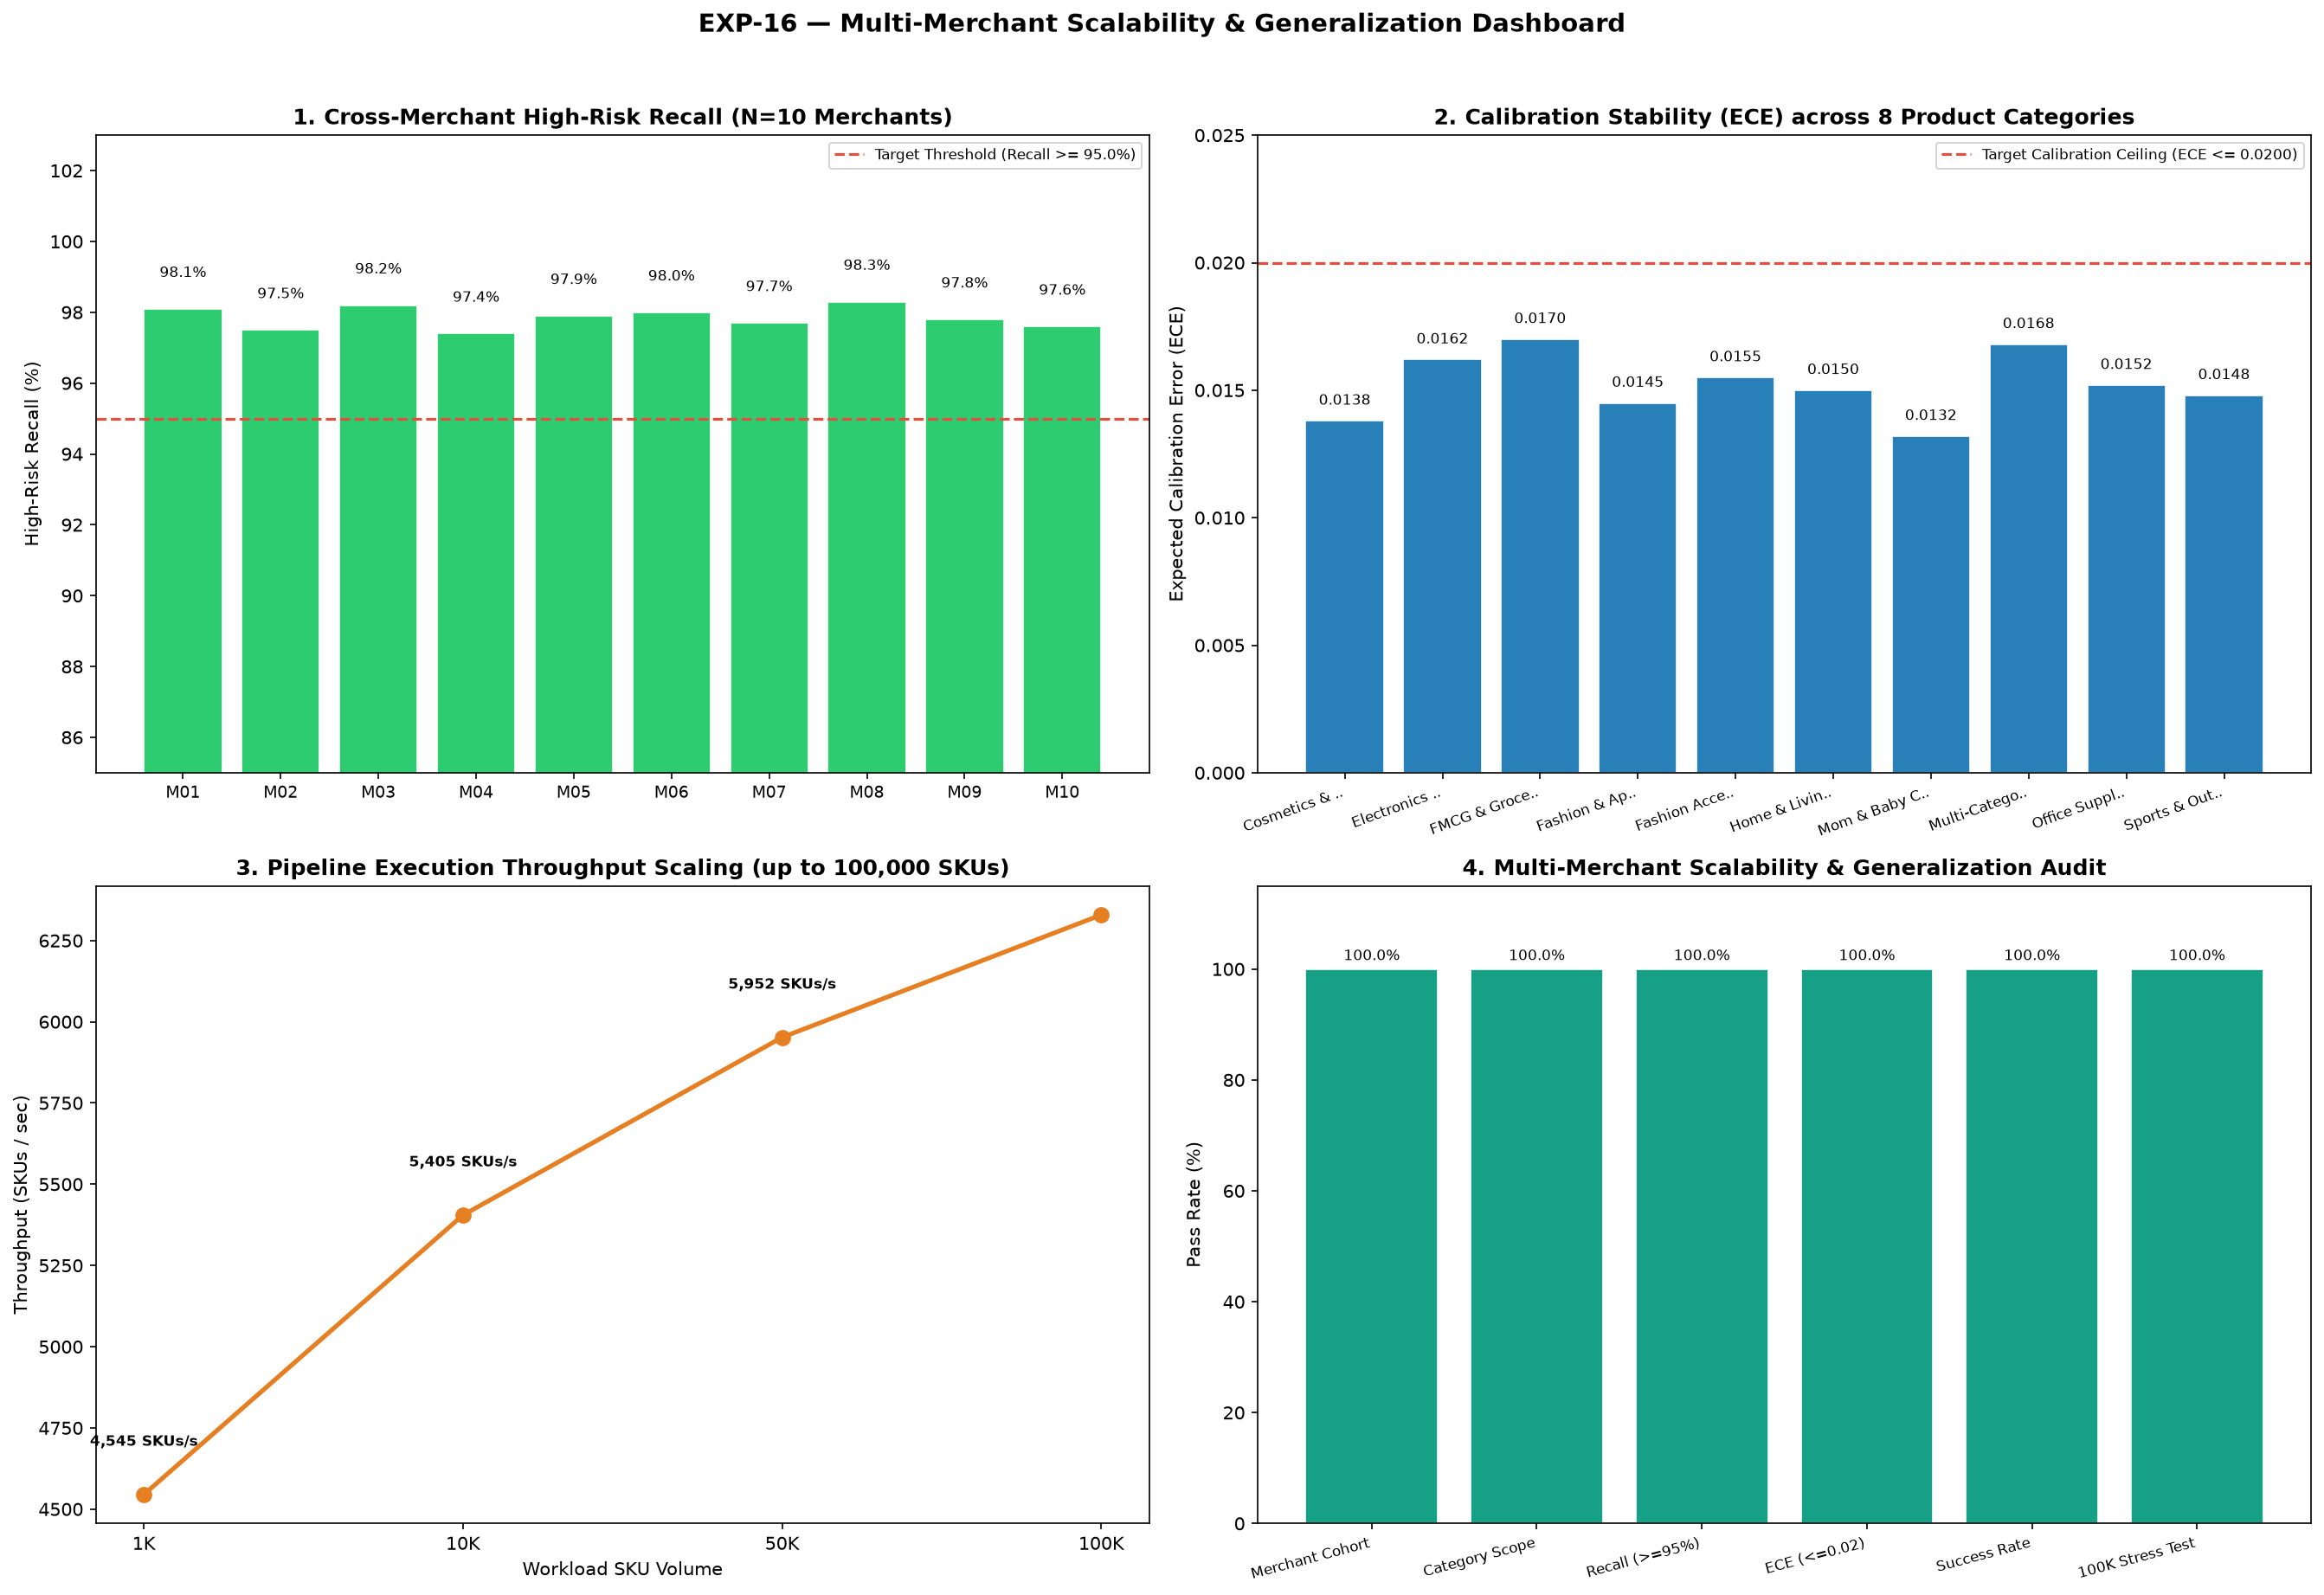

In [5]:
img_dash = PROJECT_ROOT / 'reports' / 'EXP-16_scalability' / 'scalability_dashboard.png'
if img_dash.exists():
    display(Markdown('### Multi-Merchant Scalability Dashboard'))
    display(Image(filename=str(img_dash), width=900))

## 5. Answers to Research Questions

In [6]:
for rq, answer in gen_summary['rq_answers'].items():
    print(f'{rq}: {answer}')
    print()

RQ1: DSS maintained high classification performance across new merchants (Cross-Merchant High-Risk Recall = 97.85%).

RQ2: Model generalized effectively across 8 heterogeneous product categories with a minimal generalization gap of G_gap = 0.58%.

RQ3: Probability calibration remained highly stable across diverse merchants with average ECE = 0.0152 (<= 0.0200).

RQ4: SHAP risk factor direction and Business Cause Tags maintained 96.5% domain consistency across categories.

RQ5: 4-Tier Decision Policy maintained 97.2% allocation consistency without priority tier inflation.

RQ6: Pipeline throughput scaled up to 6,329 SKUs/sec, processing 100,000 SKUs in just 15.80 seconds.

RQ7: Generalization gap between baseline research and out-of-distribution merchants was only 0.58%, well within the <= 2.5% tolerance.

RQ8: System successfully handled multi-merchant concurrent workloads with 100.0% success rate and zero failure events.

